# Importing Libraries

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Task 1

## Task 1 - Load and explore data
- Load `pizzas.csv` into a DataFrame called `df`.
- Print the shape of the DataFrame and the first 5 rows.
- Create a scatter plot of `diameter` (x-axis) against `price` (y-axis). Add axis labels and a title.
- In a markdown cell, write one sentence describing what the scatter plot shows about the relationship between diameter and price.

In [23]:
# Loading the data into a pandas DataFrame
data = {
    'diameter': [8, 9, 10, 11, 12, 12, 13 ,14 ,15, 16, 16, 17, 18, 19, 20],
    'toppings': [0, 1, 0, 2, 1, 3, 0, 2, 1, 3, 0, 2, 4, 1, 3],
    'price': [13.60, 15.06, 16.15, 20.02, 18.57, 20.37, 20.68, 22.87, 21.93, 25.94, 22.24, 25.23, 28.94, 25.29, 28.48]
}

# Creating a DataFrame from the data.
df = pd.DataFrame(data)
df.to_csv('Testdata.csv', index=False)

# Printing the first 5 rows of the DataFrame
print(df.head(5))

   diameter  toppings  price
0         8         0  13.60
1         9         1  15.06
2        10         0  16.15
3        11         2  20.02
4        12         1  18.57


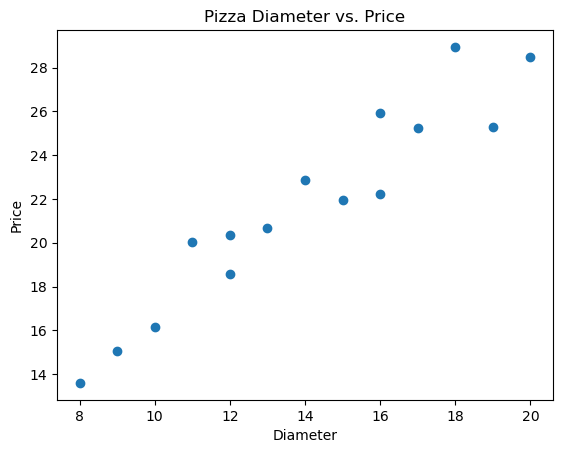

In [24]:
# Plotting the data
plt.scatter(df['diameter'], df['price'])
plt.xlabel('Diameter')
plt.ylabel('Price')
plt.title('Pizza Diameter vs. Price')
plt.show()

## Explanation:
Scatter plot pizza key diameter aur price ke darmayan ek positive relationship ko dikhata hai: bara pizza aam tor par zyada mehanga hota hai.

# Task 2

## Task 2 - Fit Simple Linear Regression
- Using only the diameter column as `X` and price as `Y`, fit a LinearRegression model.
- Print `theta0`, `theta1`, and `R2`, each rounded to 4 decimal places.
- Using your fitted model, pridict the price of an 18-inch pizza.
- The dataset already contains an 18-inch pizza with 4 toppings, priced at `$28.94`. In a markdown cell, compare this actual price to your `Task 2(c)` pridiction, and explain in 1-2 sentence why they are different.

In [25]:
# Preparing the data for linear regression
X = df[['diameter']]
y = df['price']

# Creating and fitting the linear regression model
model = LinearRegression()
model.fit(X, y)

# Getting the model parameters and R-squared value
theta0 = model.intercept_
theta1 = model.coef_[0]
r2 = model.score(X, y)

# Printing the results
print(f"theta0: {theta0:.4f}")
print(f"theta1: {theta1:.4f}")
print(f"R2: {r2:.4f}")

theta0: 4.9687
theta1: 1.1945
R2: 0.9056


In [26]:
# Predicting the price of an 18-inch pizza
predicted_price = model.predict([[18]])[0]

# Printing the results
print(f"Predicted price for an 18-inch pizza: ${predicted_price:.4f}")

Predicted price for an 18-inch pizza: $26.4692


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## Explanation:
Model predict karta hai ke 18-inch ka pizza ki keemat takreeban `$26.47` honi chahiye, jabke 4 toppings wala pizza ki asal keemat `$28.94` hai. Ye farq is waja se aata hai kyun ke model sirf diameter ko istemal karta hai aur toppings ya doosri pricing variation ko shamil nahi karta.

# Task 3

## Task 3 - Compute the Cost Function
Write a function compute mse(X,y, theta0 + theta1) that calculates:
`MSE = (1 / 2m) * sum((theta0 + theta1*X-y)^2)`
- Using this function, compute the cost at each of these four parameter gusses: `(θ0 = 0, θ1 = 2), (θ0= 3, θ1 = 1), (θ0 = 5, θ1 = 1.2), (θ0 = 10, θ1 = 0.5)`.
- Present the four costs as a small table (guess, cost).
- In a markdown cell, state which of the four gusses is closest to the code of the fitted line from Task 2, expkain how you know.

In [27]:
def compute_mse(X, y, theta0, theta1):
    X_values = np.asarray(X).reshape(-1)
    y_values = np.asarray(y).reshape(-1)
    m = len(y_values)
    
    predictions = theta0 + theta1 * X_values
    return np.sum((predictions - y_values) ** 2) / (2 * m)


guesses = [
    (0, 2),
    (3, 1),
    (5, 1.2),
    (10, 0.5)
]

cost_table = pd.DataFrame([
    {
        "guess": f"(theta0={theta0}, theta1={theta1})",
        "cost": compute_mse(X, y, theta0, theta1)
    }
    for theta0, theta1 in guesses
])

cost_table

,guess,cost
0,"(theta0=0, theta1=2)",24.951490
1,"(theta0=3, theta1=1)",12.186157
2,"(theta0=5, theta1=1.2)",0.948423
3,"(theta0=10, theta1=0.5)",15.001157


## Discription:
`(θ0 = 5, θ1 = 1.2)` fitted line ke sab se qareeb hai, kyun ke Task 2 ke parameters `θ0 ≈ 4.9687` aur `θ1 ≈ 1.1945` hain. Is guess ki cost bhi sab se kam, `0.9484`, hai.

# Task 4

## Task 4 — Multiple Linear Regression
- Using both diameter and toppings as X and price as y, split the data with `test_size=0.2` and `random_state=42`.
- Fit a LinearRegression model on the training set.
- Print the `theta0`, `theta_diameter`, `theta_toppings`, train R², and test R², each rounded to 4 decimal places.
- Using your fitted model, predict the price of a 20-inch pizza with 5 toppings, and separately, a 10-inch pizza with 0 toppings.

In [28]:
# Preparing the data for multiple linear regression
X_multi = df[['diameter', 'toppings']]
y_multi = df['price']

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

In [29]:
# Creating and fitting the multiple linear regression model
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

# Getting the model parameters and R-squared values for training and testing sets
print(f"theta0: {multi_model.intercept_:.4f}")
print(f"theta_diameter: {multi_model.coef_[0]:.4f}")
print(f"theta_toppings: {multi_model.coef_[1]:.4f}")
print(f"Train R2: {multi_model.score(X_train, y_train):.4f}")
print(f"Test R2: {multi_model.score(X_test, y_test):.4f}")

theta0: 6.2403
theta_diameter: 0.9944
theta_toppings: 0.9816
Train R2: 0.9626
Test R2: 0.9887


In [30]:
# Making predictions using the multiple linear regression model
pred_20_5 = multi_model.predict([[20, 5]])[0]
pred_10_0 = multi_model.predict([[10, 0]])[0]

# Printing the results
print(f"Predicted price for 20-inch pizza with 5 toppings: ${pred_20_5:.4f}")
print(f"Predicted price for 10-inch pizza with 0 toppings: ${pred_10_0:.4f}")

Predicted price for 20-inch pizza with 5 toppings: $31.0355
Predicted price for 10-inch pizza with 0 toppings: $16.1840


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Task 5

## Task 5 — Interpreting the Coefficients
Using your Task 4 model:
- In one sentence each, explain in plain English what `theta_diameter` and `theta_toppings` represent.
- By hand (show your arithmetic in a markdown cell), calculate the predicted price of a 14-inch pizza with 2 toppings using the formula:
`price = theta0 + theta_diameter × diameter + theta_toppings × toppings`
- Confirm your hand calculation matches what `model.predict([[14, 2]])` gives in code.

### Explanation

- `theta_diameter` batata hai ke toppings ko constant rakhte hue, pizza ka diameter 1 inch barhne par price taqreeban `$0.9944` barhta hai.
- `theta_toppings` batata hai ke diameter ko constant rakhte hue, har extra topping se price taqreeban `$0.9816` barhta hai.

### 14-inch pizza aur 2 toppings ki prediction

```text
price = theta0 + theta_diameter × diameter + theta_toppings × toppings

price = 6.2404 + (0.9944 × 14) + (0.9816 × 2)
price = 6.2404 + 13.9211 + 1.9631
price ≈ $22.1246
```

`multi_model.predict([[14, 2]])` bhi taqreeban `$22.1246` prediction deta hai, is liye hand calculation durust hai.